In [1]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt
import pickle

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold


from utils import read_utils
from utils import plot_utils
from utils import train_utils

sys.path.append(os.path.join(os.getcwd(), '../../'))
from models import bom
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/../../models/hgm.py'>

In [3]:
default_hyperparameters = {
	'dimensions': 1,
	'loss1_lambda': 0.67,
	'loss2_lambda': 1.0 - 0.67,
	'w1_reg_lambda': 0.0,
	'w2_reg_lambda': 0.0,
}

# Functions

In [4]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

In [5]:
def separate_losses(file_ids, columns, models_spn_man_rec_res_pres):
	models_spn = [
		[
			pd.DataFrame(data=np.array(split[0])[None], columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	models_man = [
		[
			pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(np.array(split[1]).shape[1])]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	(models_rec,
	 models_res,
	 models_pres) = tuple(
		[
			[
				pd.DataFrame(data=np.array(split[m]), columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
			] for i in range(len(file_ids))
		] for m in [2, 3, 4]
	)
	return models_spn, models_man, models_rec, models_res, models_pres

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & prep

In [7]:
ll = 'll67'

with open('./sweep/hyperparams.pkl', 'rb') as f:
    swept_hyperparameters = pickle.load(f)

bom_reg_lambdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	'w1_reg_lambda': swept_hyperparameters[ll]['bom']['w1_reg_lambda']['mean']['geometric'],
}
hgm_reg_lambdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	# 'w2_reg_lambda': default_hyperparameters['w2_reg_lambda'],
	'w1_reg_lambda': swept_hyperparameters[ll]['hgm']['w1_reg_lambda']['mean']['geometric'],
	'w2_reg_lambda': swept_hyperparameters[ll]['hgm']['w2_reg_lambda']['mean']['geometric'],
}


selection_n = 5
selection_bhl = ['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move']


# read_ids = list(range(0, 13+1))
# read_ids = [0, 2, 3, 8, 9]
read_ids = [0]
plot_id = 0

In [8]:
# read

path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer/brain')

(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [9]:
# prep
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(data=trace.values[1:, :], columns=trace.columns) for trace in traces]
traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

states = [pd.DataFrame(data=state.values[1:, :], columns=state.columns) for state in states]

markers = [pd.DataFrame(data=marker.values[1:, :] - marker.values[:-1, :], columns=marker.columns) for marker in markers]
markers = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers
]

# read models

In [10]:
bom_load_name = os.path.join(ll, f'bom_w1-{bom_reg_lambdas['w1_reg_lambda']:.2E}')
hgm_load_name = os.path.join(ll, f'hgm_w1-{hgm_reg_lambdas['w1_reg_lambda']:.2E}_w2-{hgm_reg_lambdas['w2_reg_lambda']:.2E}')

In [11]:
boms_params = train_utils.load_params(bom_load_name, filenames)

boms_losses_all = train_utils.load_losses(bom_load_name, filenames)
boms_losses_train = [losses[0] for losses in boms_losses_all]
boms_man_losses_train = [losses[1] for losses in boms_losses_all]
boms_res_losses_train = [losses[2] for losses in boms_losses_all]
boms_mpe_losses_train = [losses[3] for losses in boms_losses_all]
boms_losses = [losses[4] for losses in boms_losses_all]
boms_man_losses = [losses[5] for losses in boms_losses_all]
boms_res_losses = [losses[6] for losses in boms_losses_all]
boms_mpe_losses = [losses[7] for losses in boms_losses_all]

hgms_params = train_utils.load_params(hgm_load_name, filenames)

hgms_losses_all = train_utils.load_losses(hgm_load_name, filenames)
hgms_losses_train = [losses[0] for losses in hgms_losses_all]
hgms_man_losses_train = [losses[1] for losses in hgms_losses_all]
hgms_res_losses_train = [losses[2] for losses in hgms_losses_all]
hgms_mpe_losses_train = [losses[3] for losses in hgms_losses_all]
hgms_losses = [losses[4] for losses in hgms_losses_all]
hgms_man_losses = [losses[5] for losses in hgms_losses_all]
hgms_res_losses = [losses[6] for losses in hgms_losses_all]
hgms_mpe_losses = [losses[7] for losses in hgms_losses_all]

 # gcamp

### losses

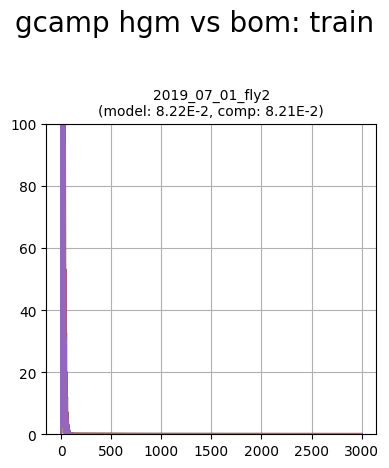

In [12]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: train',
							  filenames,
							  hgms_losses_train, boms_losses_train,
							  ylimits=(0, 100))

In [13]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: man train',
# 							  filenames,
# 							  hgms_man_losses_train, boms_man_losses_train,
# 							  ylimits=None)

In [14]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: res train',
# 							  filenames,
# 							  hgms_res_losses_train, boms_res_losses_train,
# 							  ylimits=None)

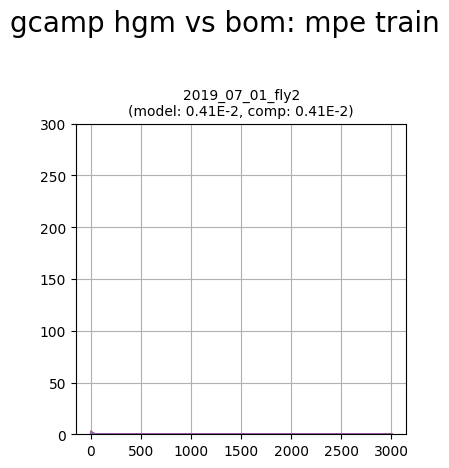

In [15]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe train',
							  filenames,
							  hgms_mpe_losses_train, boms_mpe_losses_train,
							  ylimits=(0, 300))

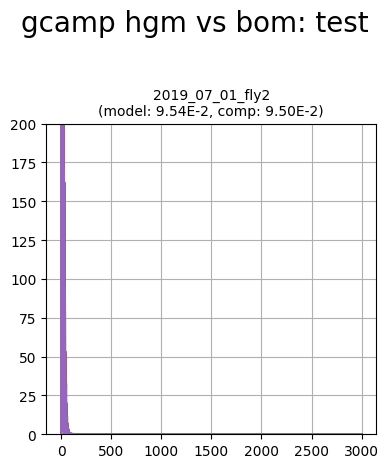

In [16]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: test',
							  filenames,
							  hgms_losses, boms_losses,
							  ylimits=(0, 200))

In [17]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: man test',
# 							  filenames,
# 							  hgms_man_losses, boms_man_losses,
# 							  ylimits=None)

In [18]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: res test',
# 							  filenames,
# 							  hgms_res_losses, boms_res_losses,
# 							  ylimits=None)

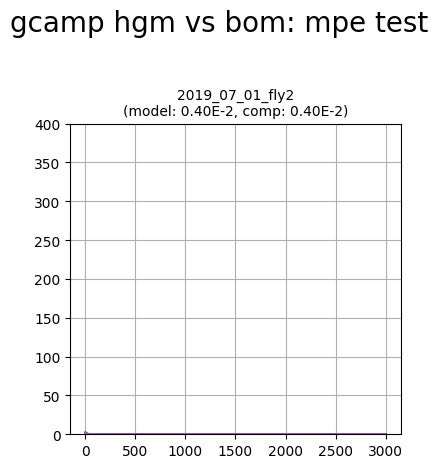

In [19]:
plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe test',
							  filenames,
							  hgms_mpe_losses, boms_mpe_losses,
							  ylimits=(0, 400))

### predict & score

In [20]:
splits = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces[i].shape[0]), states[i][['still']].values)) for i in range(len(file_ids))]

In [21]:
boms_spn_man_rec_res_pres = [[
	bom.score_fn(params, traces[i].values[eval], markers[i].values[eval]) for params, (train, eval) in zip(boms_params[i], splits[i])
] for i in range(len(file_ids))]

hgms_spn_man_rec_res_pres = [[
	hgm.score_fn(params, traces[i].values[eval], markers[i].values[eval]) for params, (train, eval) in zip(hgms_params[i], splits[i])
] for i in range(len(file_ids))]

(boms_spn,
 boms_man,
 boms_rec,
 boms_res,
 boms_pres) = separate_losses(file_ids, [trace.columns for trace in traces], boms_spn_man_rec_res_pres)

(hgms_spn,
 hgms_man,
 hgms_rec,
 hgms_res,
 hgms_pres) = separate_losses(file_ids, [trace.columns for trace in traces], hgms_spn_man_rec_res_pres)

### performance

In [22]:
neuron_scores = assemble(boms_spn, hgms_spn)

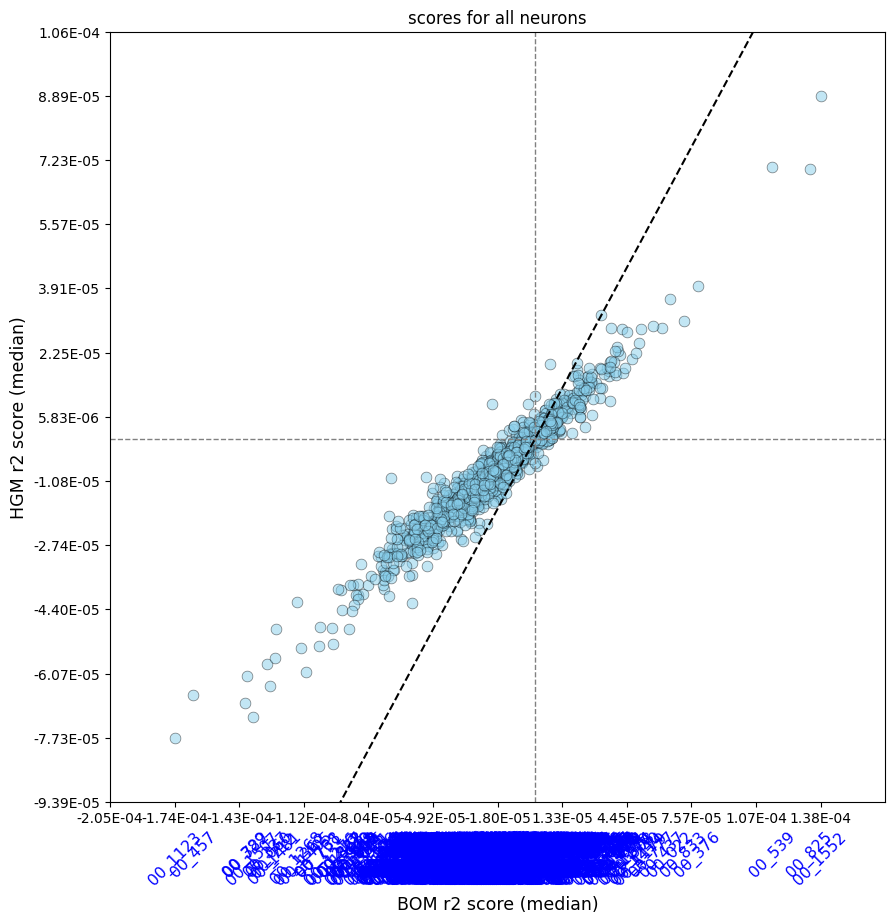

In [23]:
plot_utils.plot_performance_plot(neuron_scores, None,
								 title='scores for all neurons', limits=None)

In [24]:
# plot_utils.plot_performance_plot({key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()}, None,
# 								title='scores for ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55))

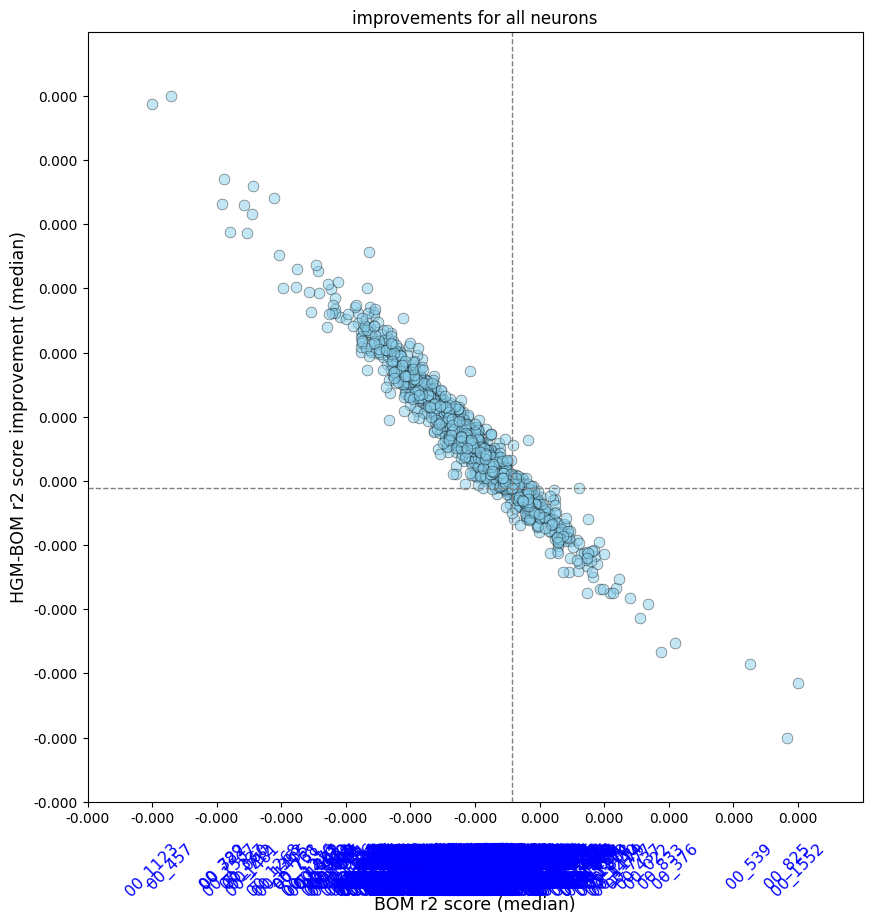

In [25]:
plot_utils.plot_improvement_plot(neuron_scores, None,
								 title='improvements for all neurons')

In [26]:
selection_n_traces = [elem[0] for elem in list(reversed(sorted(neuron_scores.items(), key=lambda x: x[1][0])))[:5]]

### traces

In [27]:
boms_spn_man_rec_res_pres = [[
	bom.score_fn(params, traces[i].values, markers[i].values) for params in boms_params[i]
] for i in range(len(file_ids))]

hgms_spn_man_rec_res_pres = [[
	hgm.score_fn(params, traces[i].values, markers[i].values) for params in hgms_params[i]
] for i in range(len(file_ids))]

(boms_spn_full,
 boms_man_full,
 boms_rec_full,
 boms_res_full,
 boms_pres_full) = separate_losses(file_ids, [trace.columns for trace in traces], boms_spn_man_rec_res_pres)

(hgms_spn_full,
 hgms_man_full,
 hgms_rec_full,
 hgms_res_full,
 hgms_pres_full) = separate_losses(file_ids, [trace.columns for trace in traces], hgms_spn_man_rec_res_pres)

In [28]:
_, _, traces_cca_rec, _, _, _, _, _ = train_utils.get_manifolds_cca(traces, states, n_cv=default_hyperparameters['dimensions'], n_pc=0)
traces_cca_res = [pd.DataFrame(data=trace.values - trace_cca_rec.values, columns=trace.columns) for trace, trace_cca_rec in zip(traces, traces_cca_rec)]

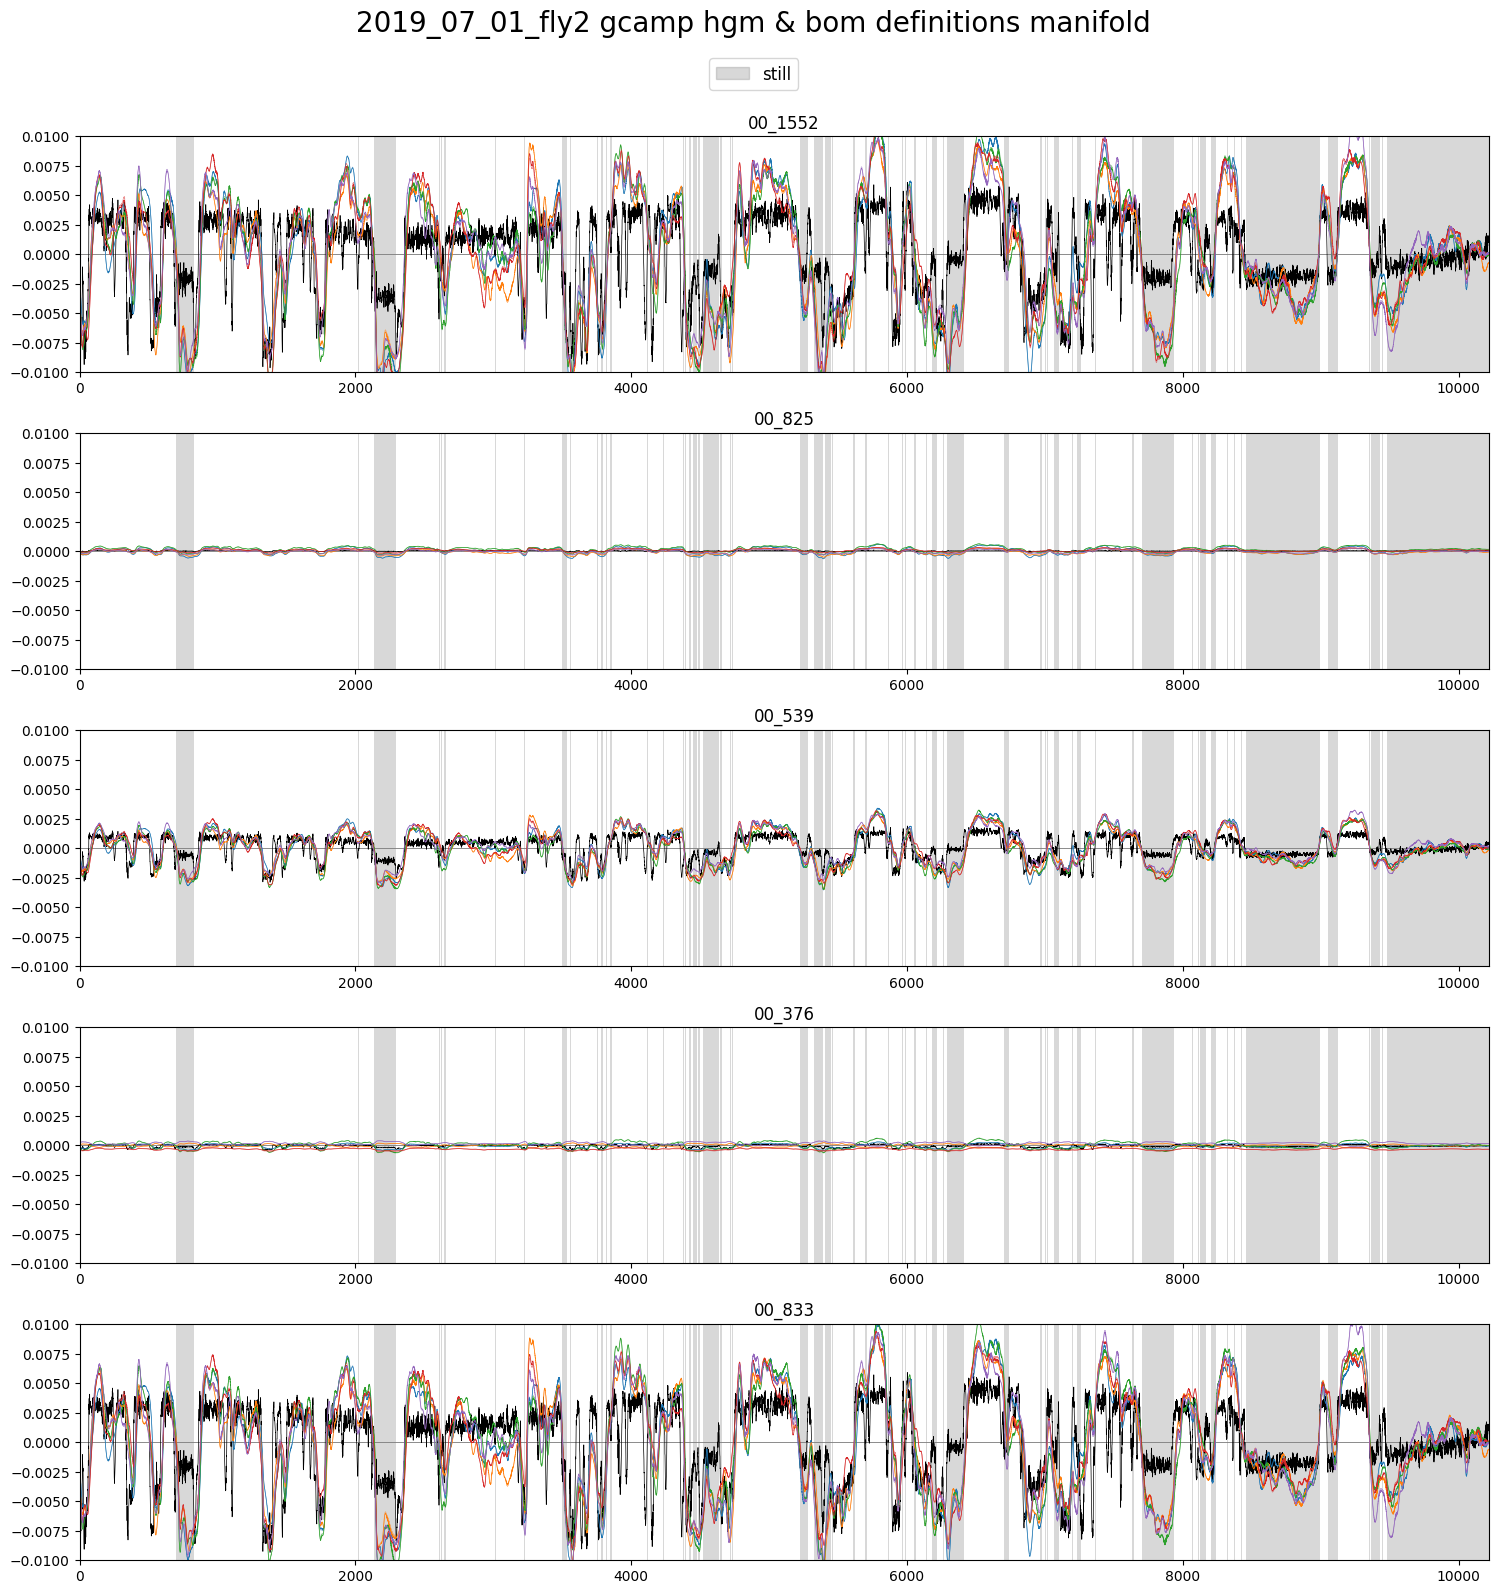

In [29]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames[file_ids.index(plot_id)]} gcamp hgm & bom definitions manifold',
	states[file_ids.index(plot_id)][['still']],
	traces_cca_rec[file_ids.index(plot_id)][selection_n_traces],
	[hgms_rec_full[file_ids.index(plot_id)][i][selection_n_traces] for i in range(splits)],
	[boms_rec_full[file_ids.index(plot_id)][i][selection_n_traces] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=(-0.01, 0.01),
	save_name=None)  #'GCAMP_MAN'

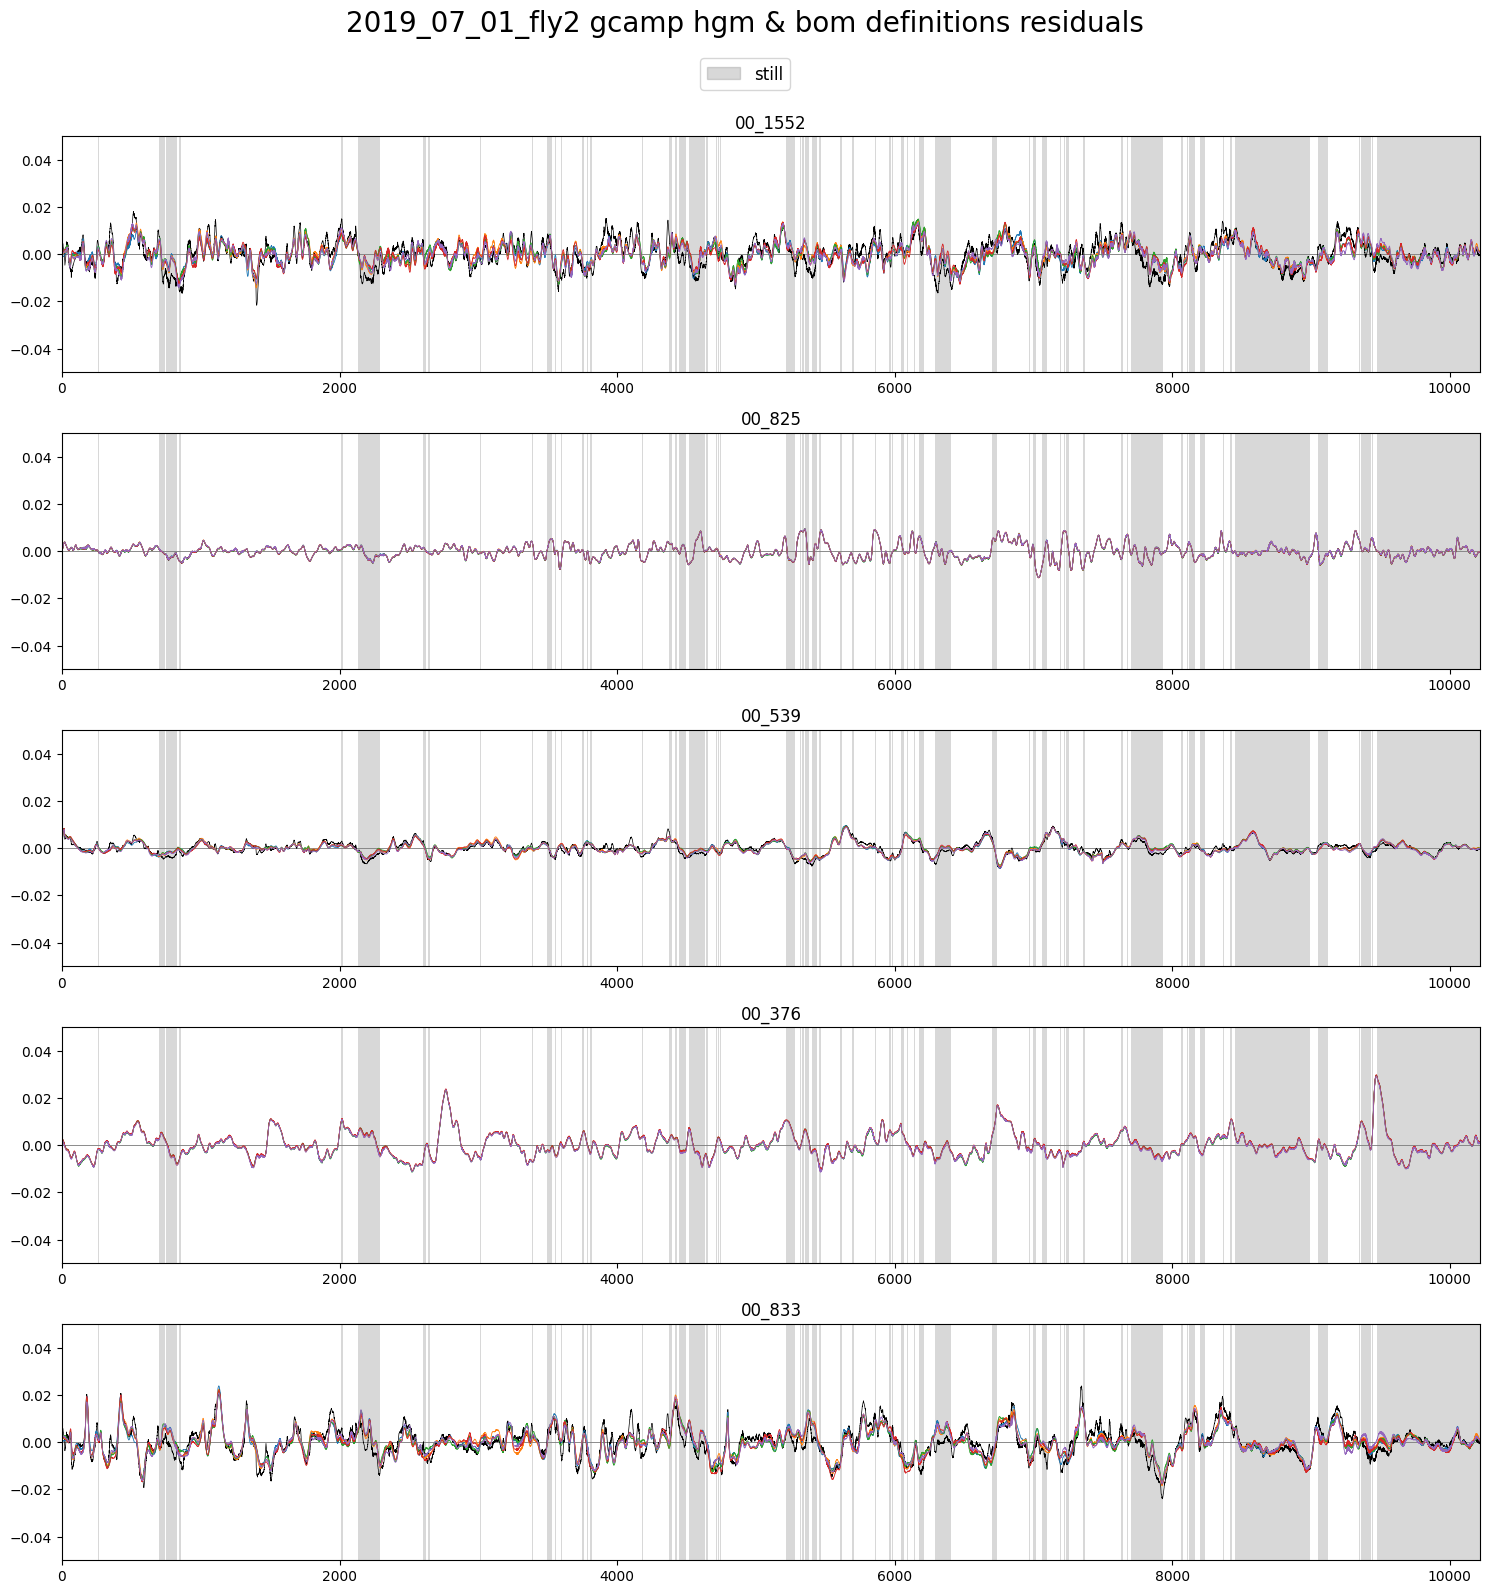

In [30]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames[file_ids.index(plot_id)]} gcamp hgm & bom definitions residuals',
	states[file_ids.index(plot_id)][['still']],
	traces_cca_res[file_ids.index(plot_id)][selection_n_traces],
	[hgms_res_full[file_ids.index(plot_id)][i][selection_n_traces] for i in range(splits)],
	[boms_res_full[file_ids.index(plot_id)][i][selection_n_traces] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=(-0.05, 0.05),
	save_name=None)  #'GCAMP_RES'

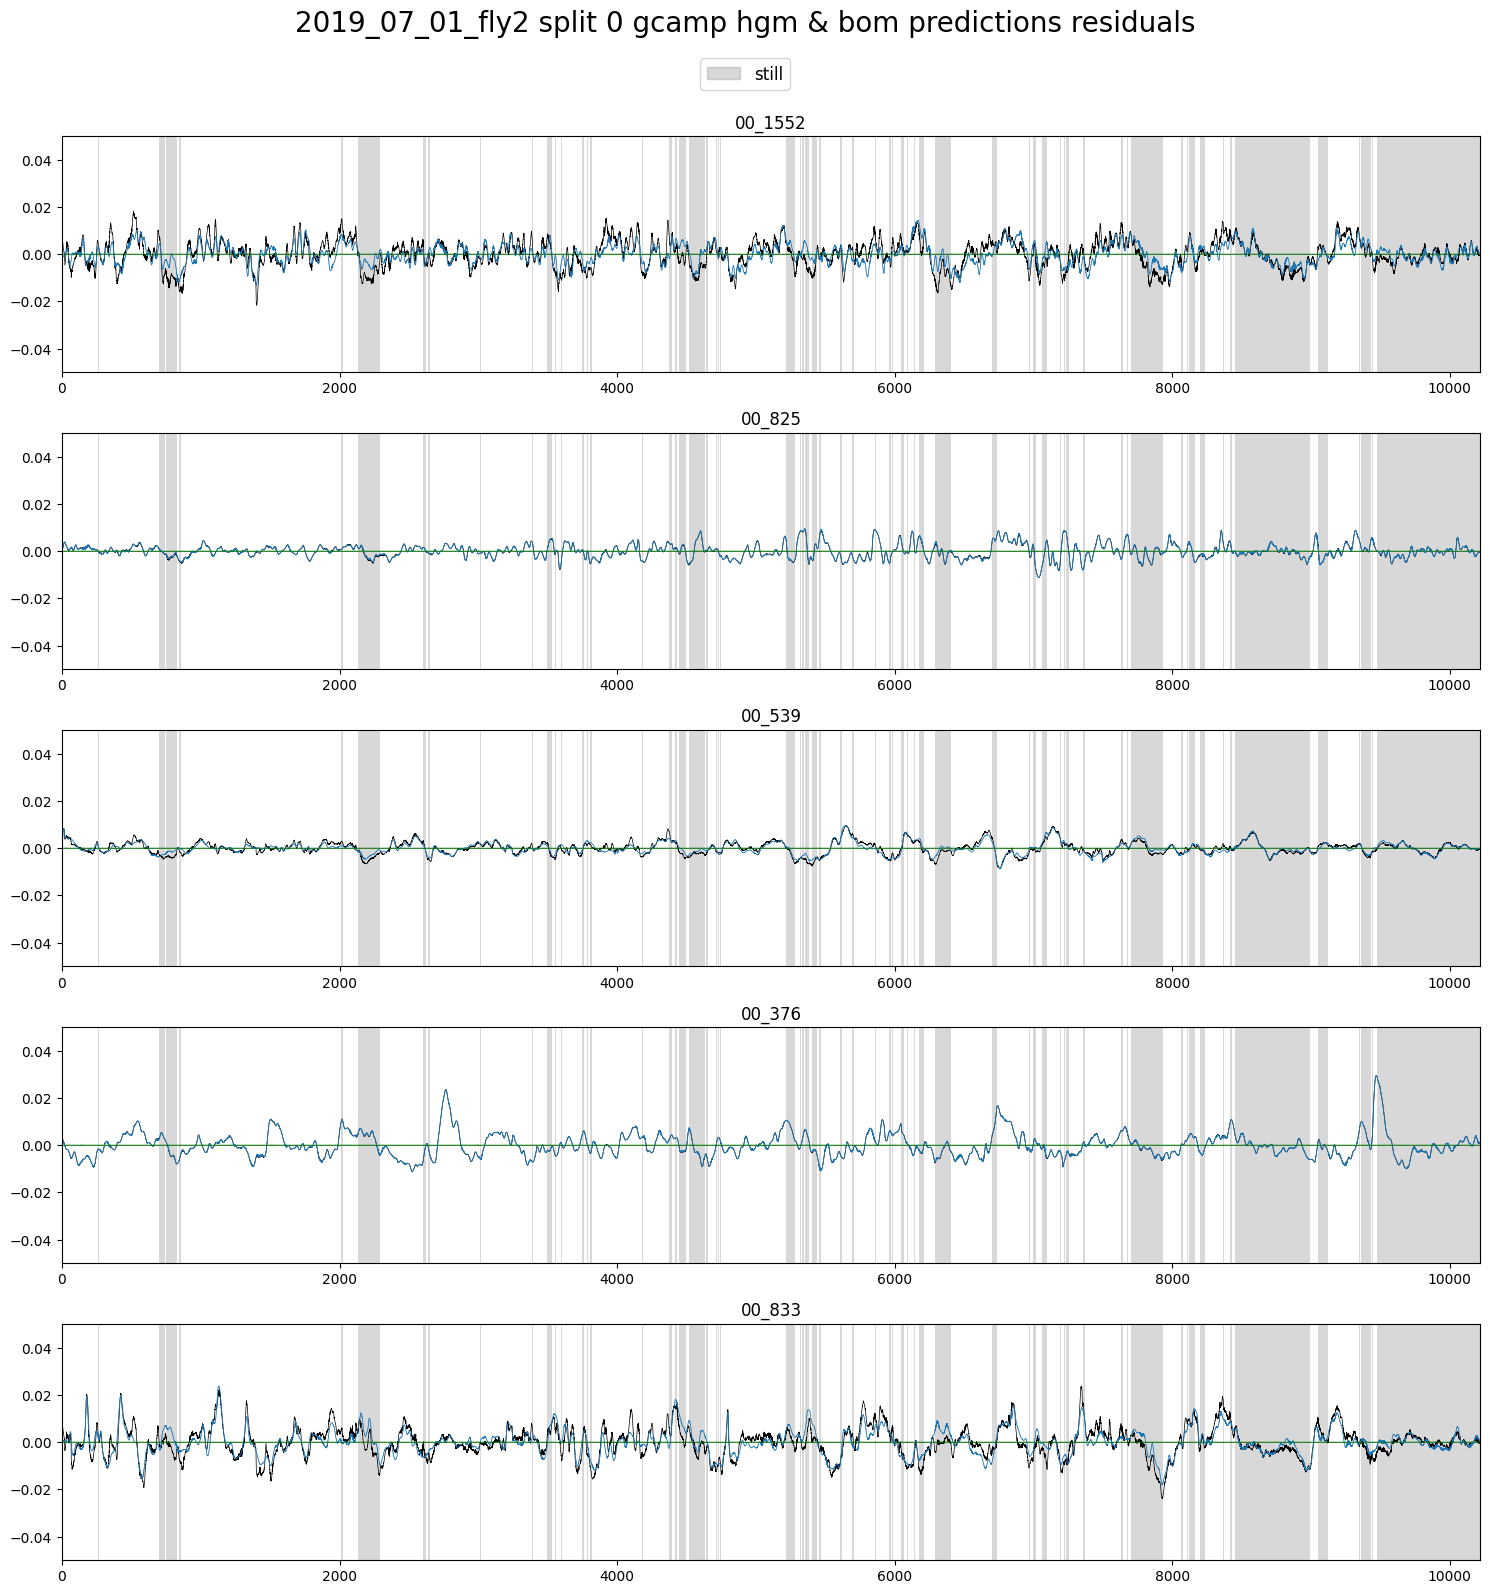

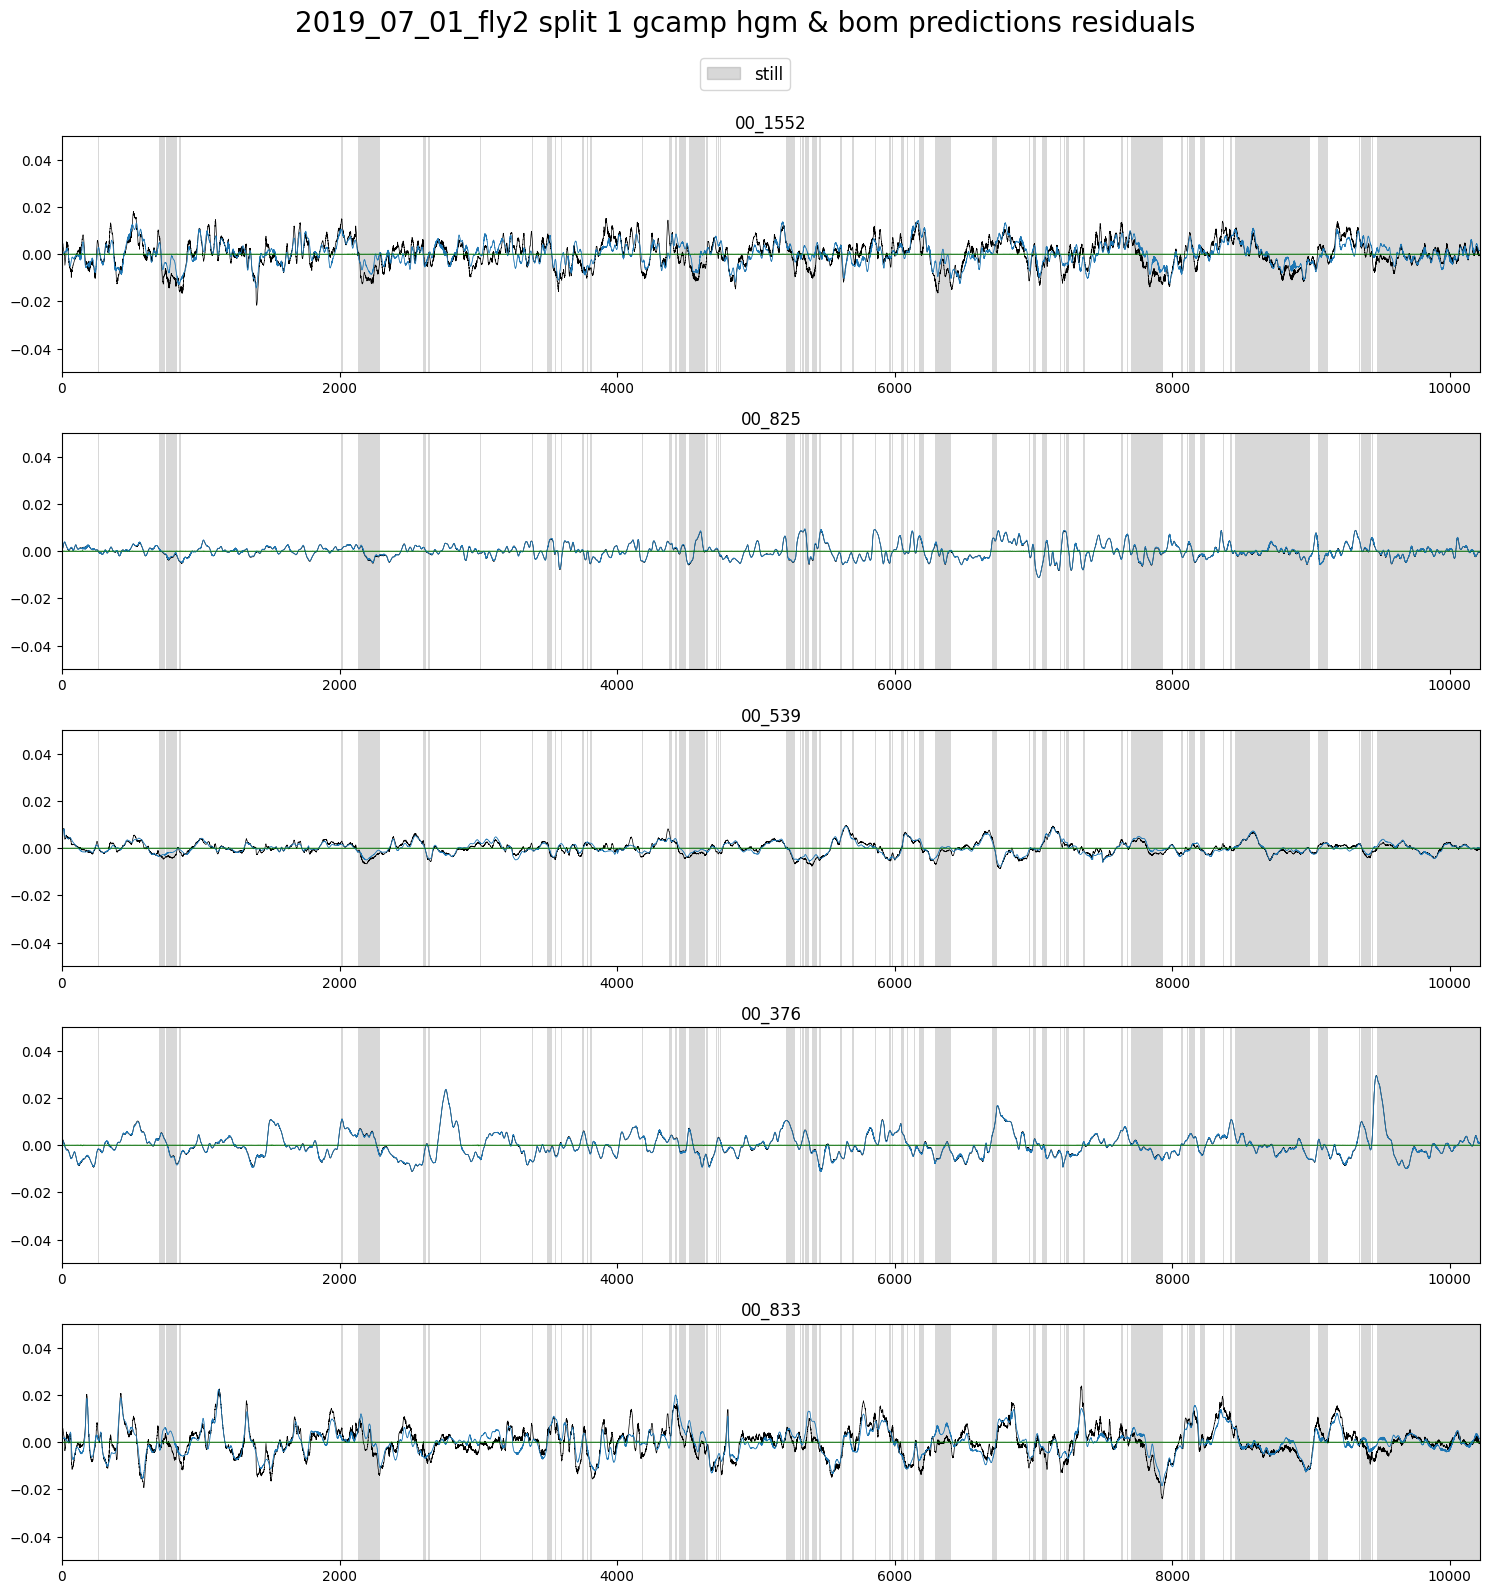

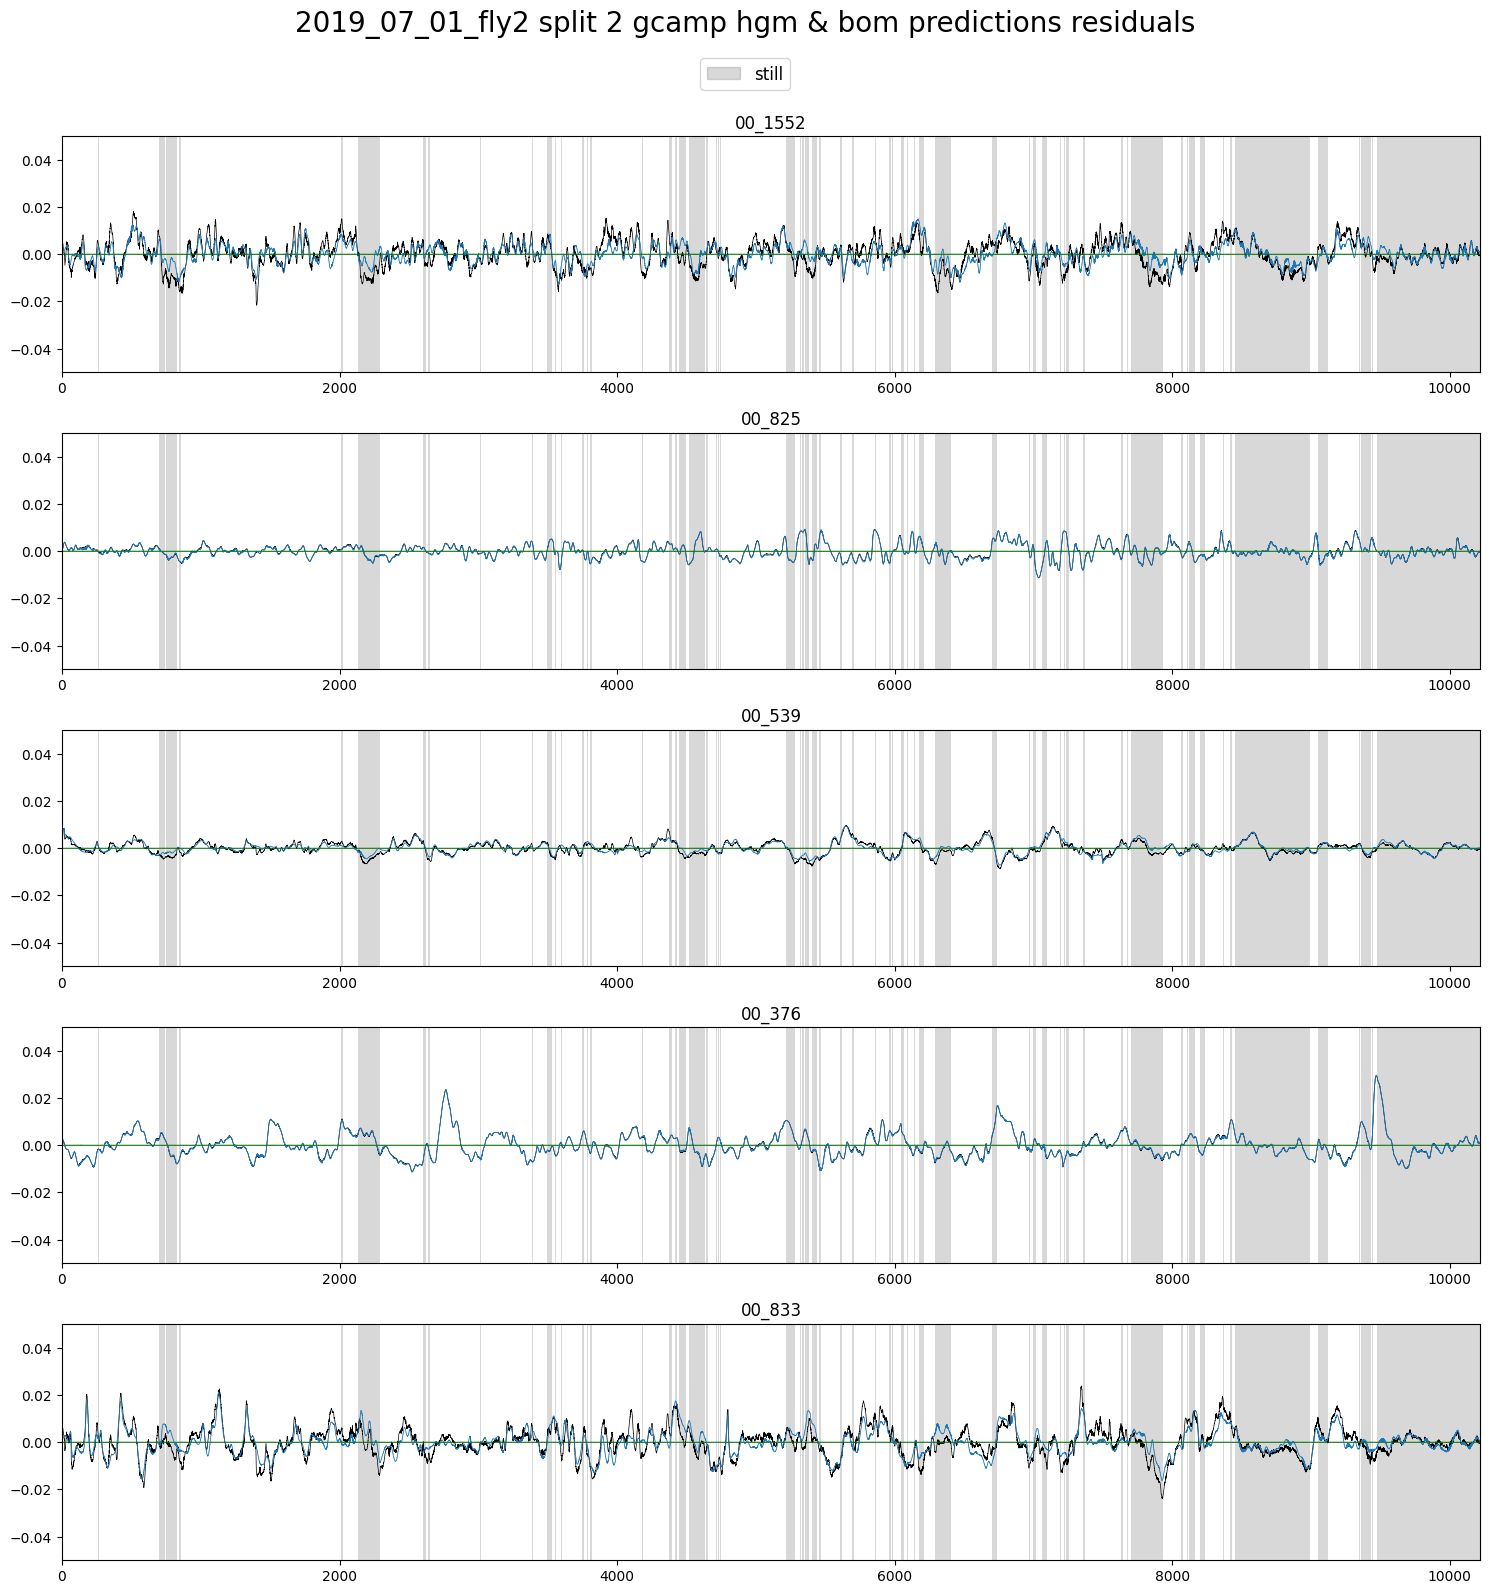

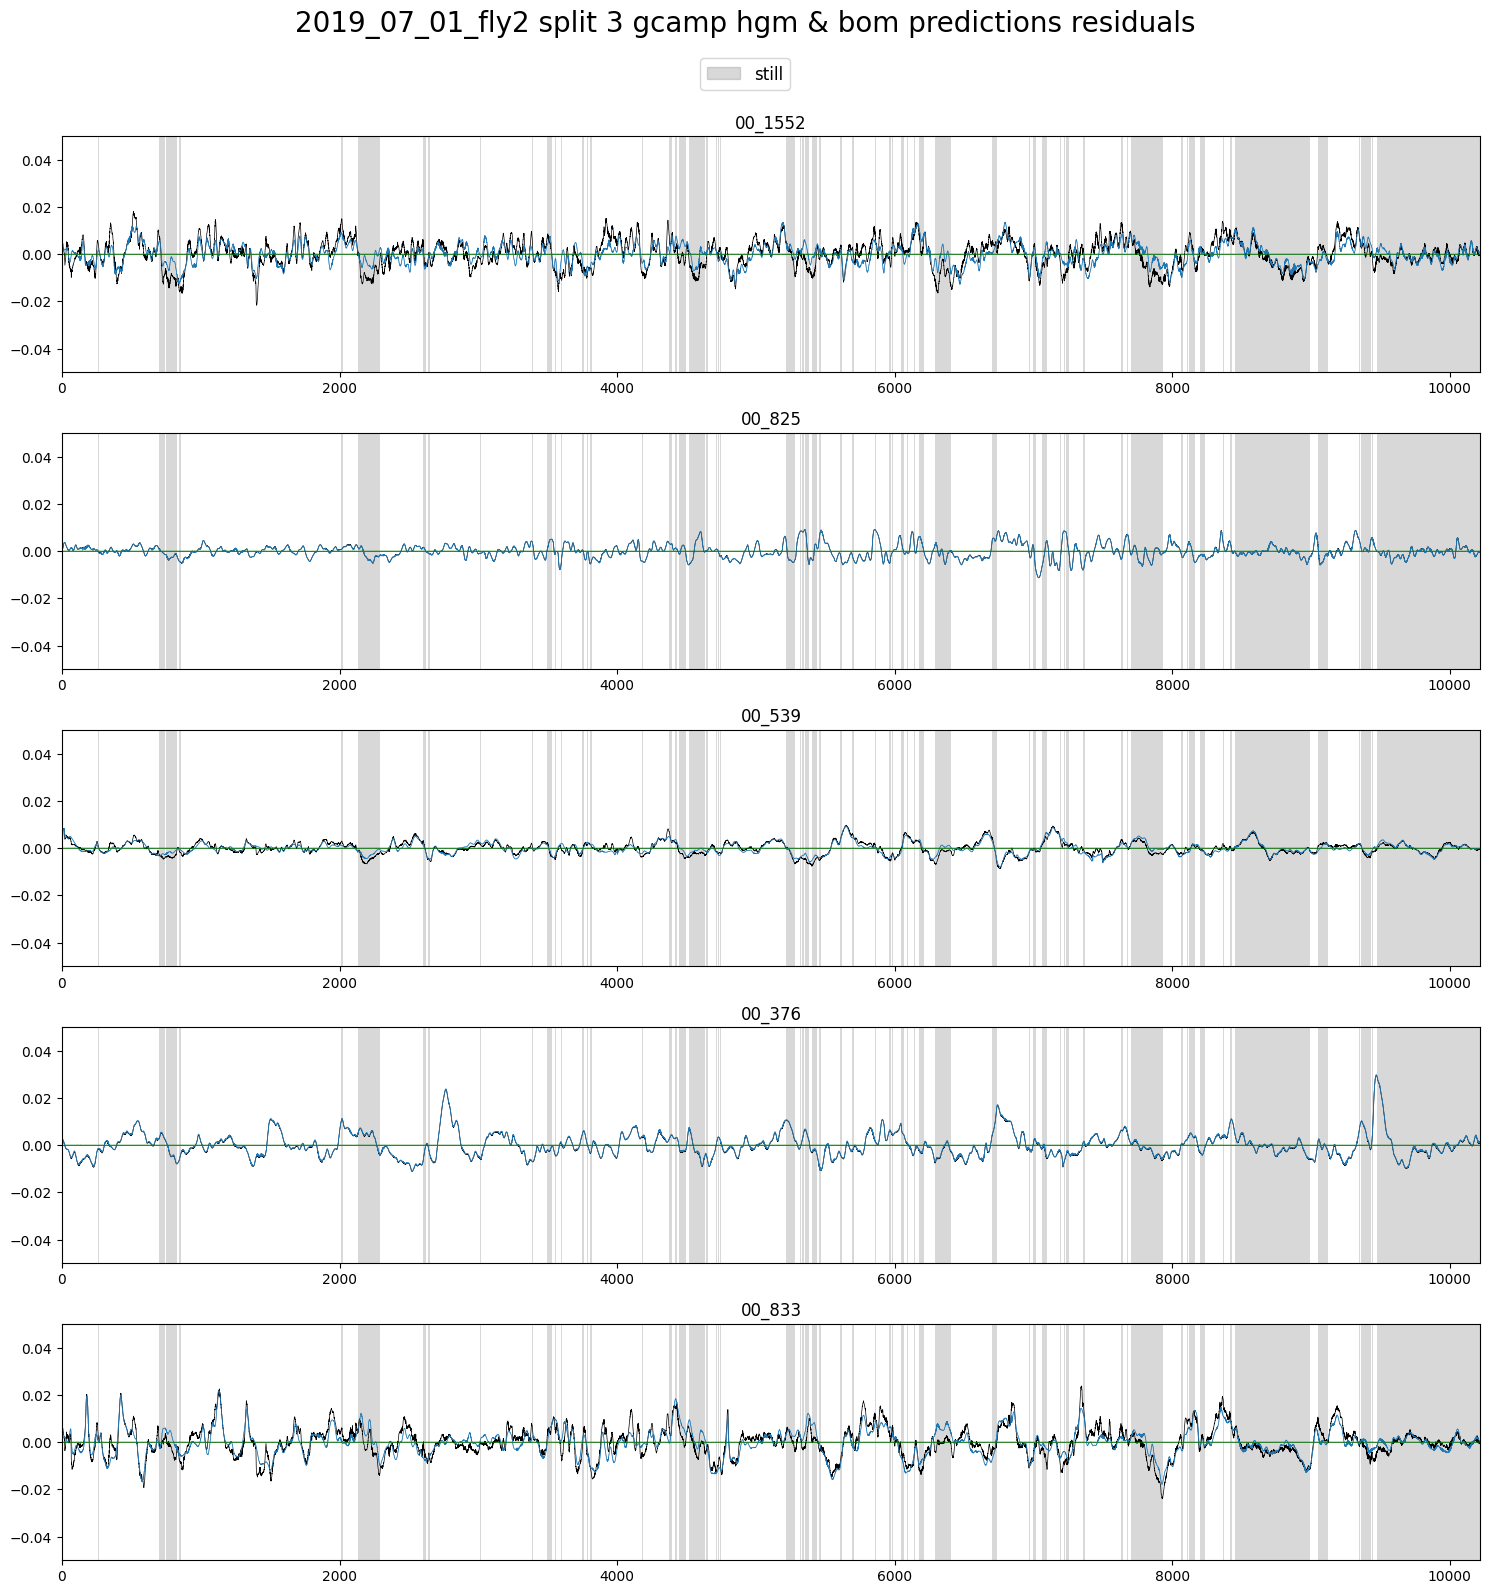

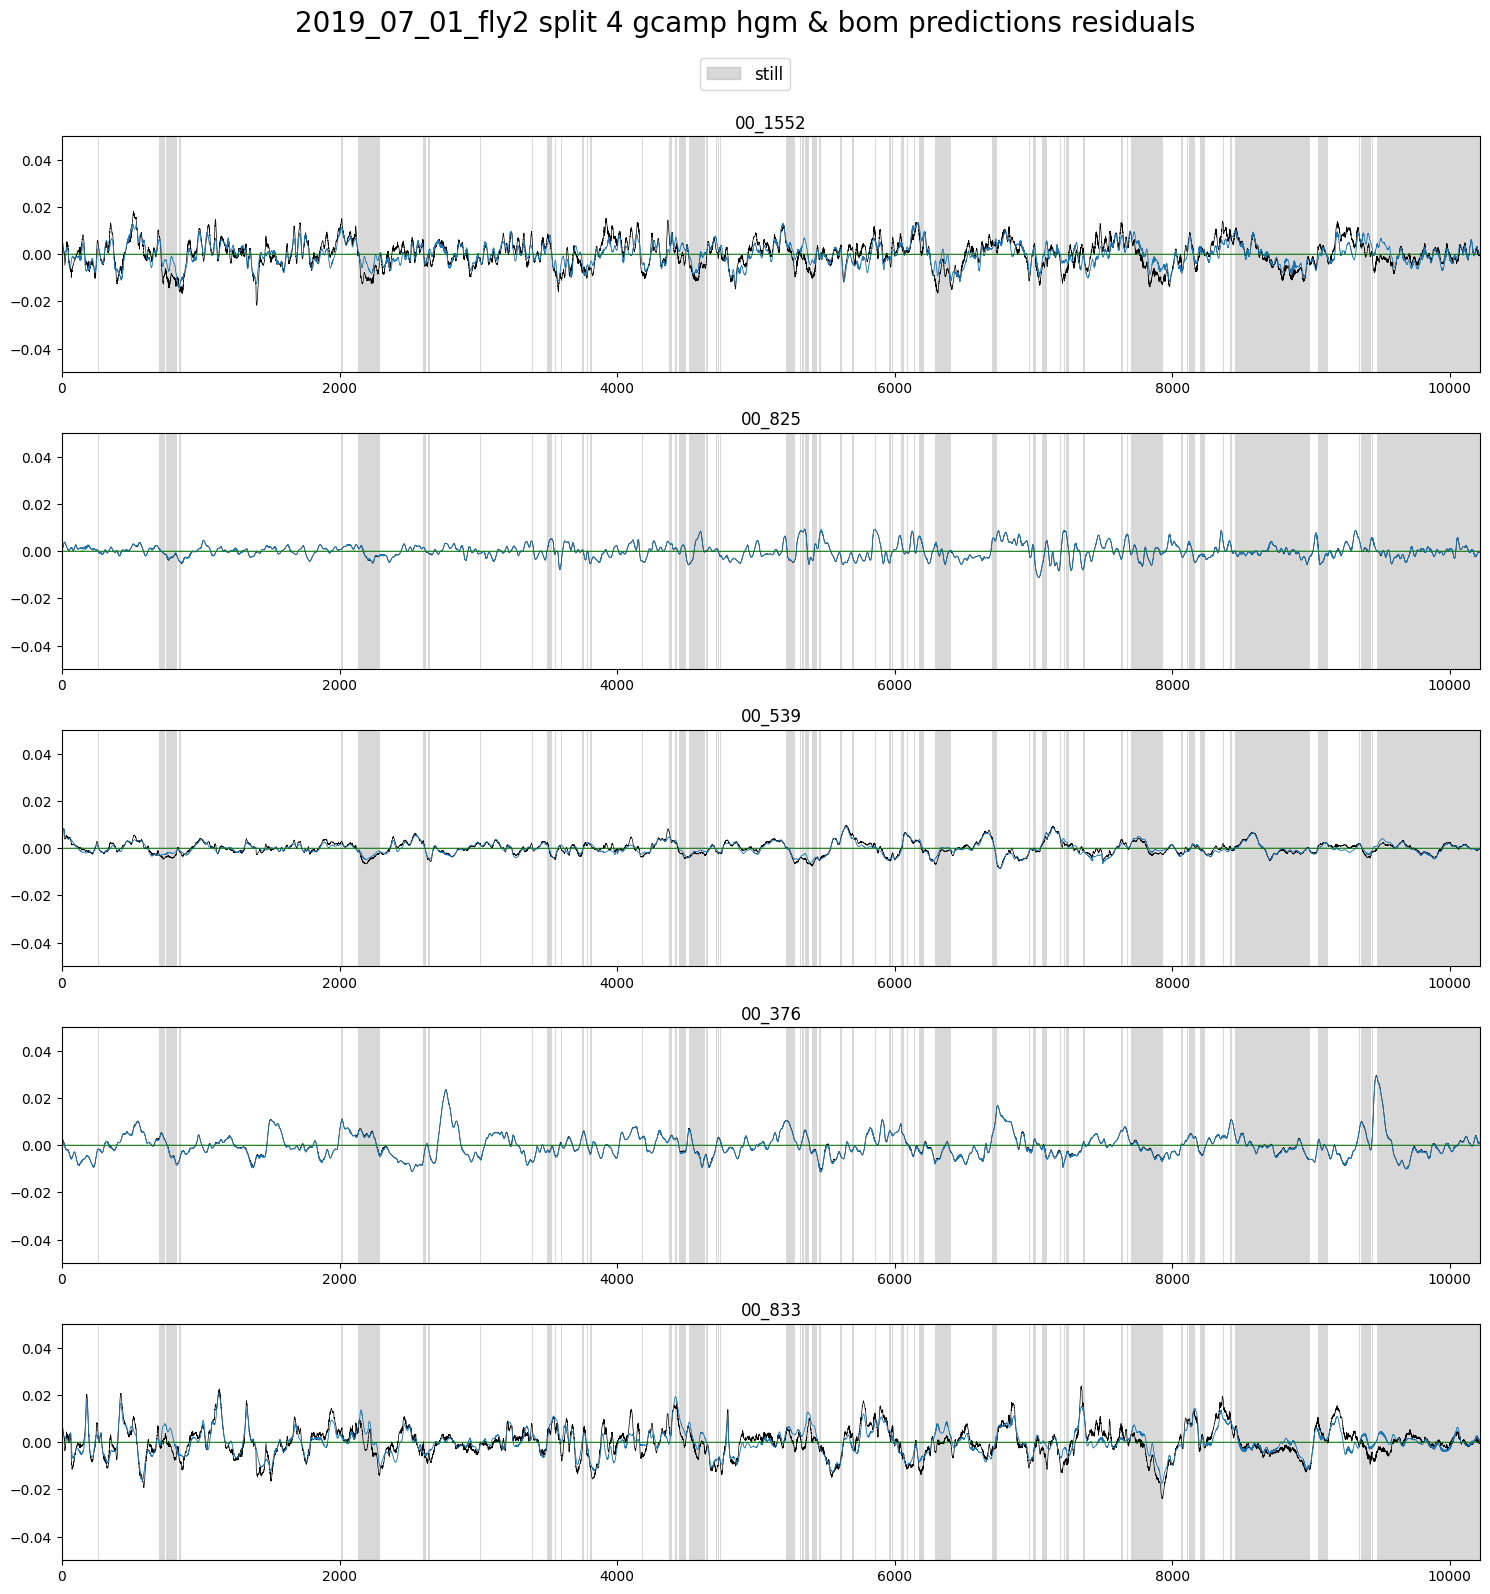

In [31]:
for i in range(5):
	plot_utils.plot_traces_comparisons(
		f'{filenames[file_ids.index(plot_id)]} split {i} gcamp hgm & bom predictions residuals',
		states[file_ids.index(plot_id)][['still']],
		traces_cca_res[file_ids.index(plot_id)][selection_n_traces],
		[hgms_res_full[file_ids.index(plot_id)][i][selection_n_traces],
		 hgms_pres_full[file_ids.index(plot_id)][i][selection_n_traces]],
		[boms_res_full[file_ids.index(plot_id)][i][selection_n_traces],
		 boms_pres_full[file_ids.index(plot_id)][i][selection_n_traces]],
		plot_first=True, plots_per_row=1, ylimits=(-0.05, 0.05),
		save_name=None)  #f'GCAMP_PRES_S{i}'

# good neurons

In [32]:
neuron_scores_filtered = {key: value for key, value in neuron_scores.items() if 0 < value[0] < value[1]}

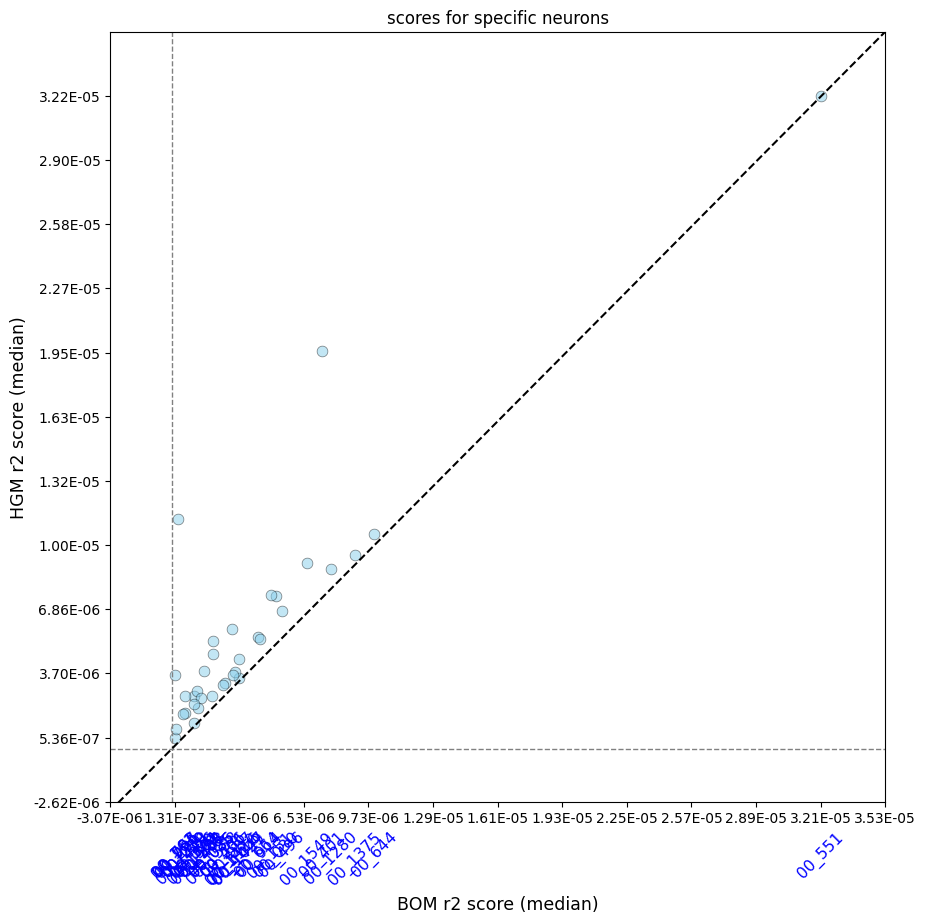

In [33]:
plot_utils.plot_performance_plot(neuron_scores_filtered, None,
								 title='scores for specific neurons', limits=None)

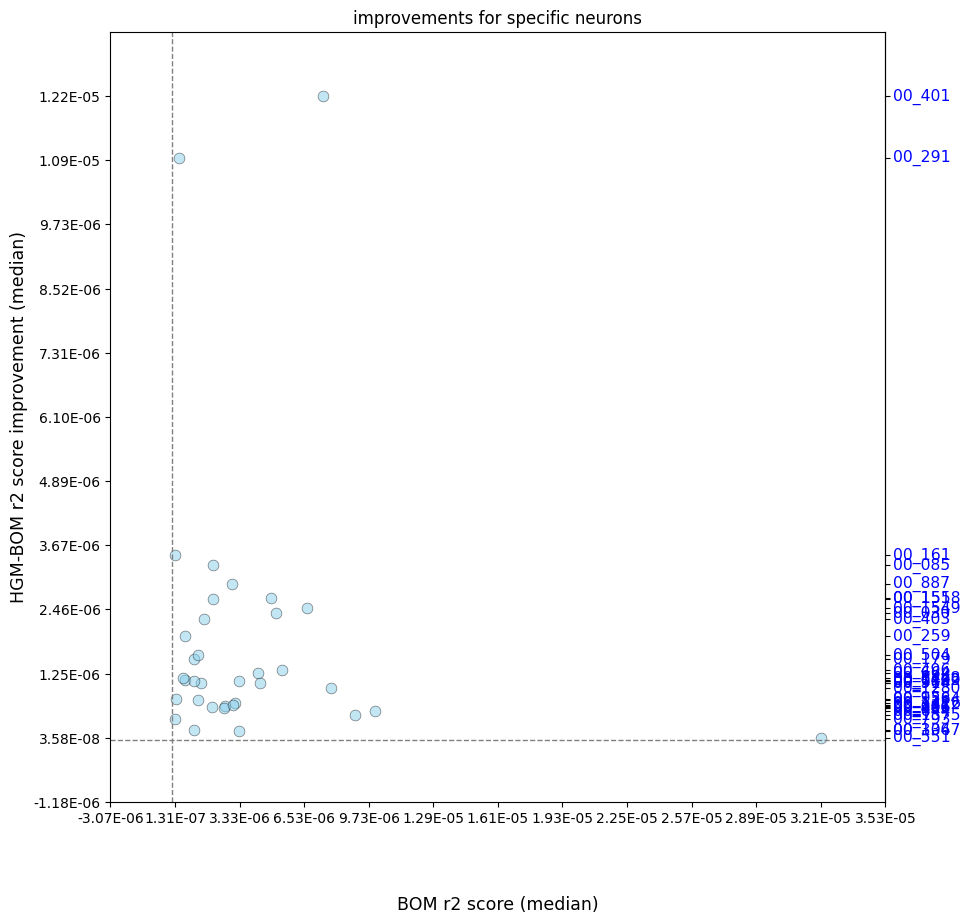

In [34]:
plot_utils.plot_improvement_plot_y(neuron_scores_filtered, None,
								   title='improvements for specific neurons', limits=None)

In [35]:
neurons_handpicked = ['00_551', '00_1549']

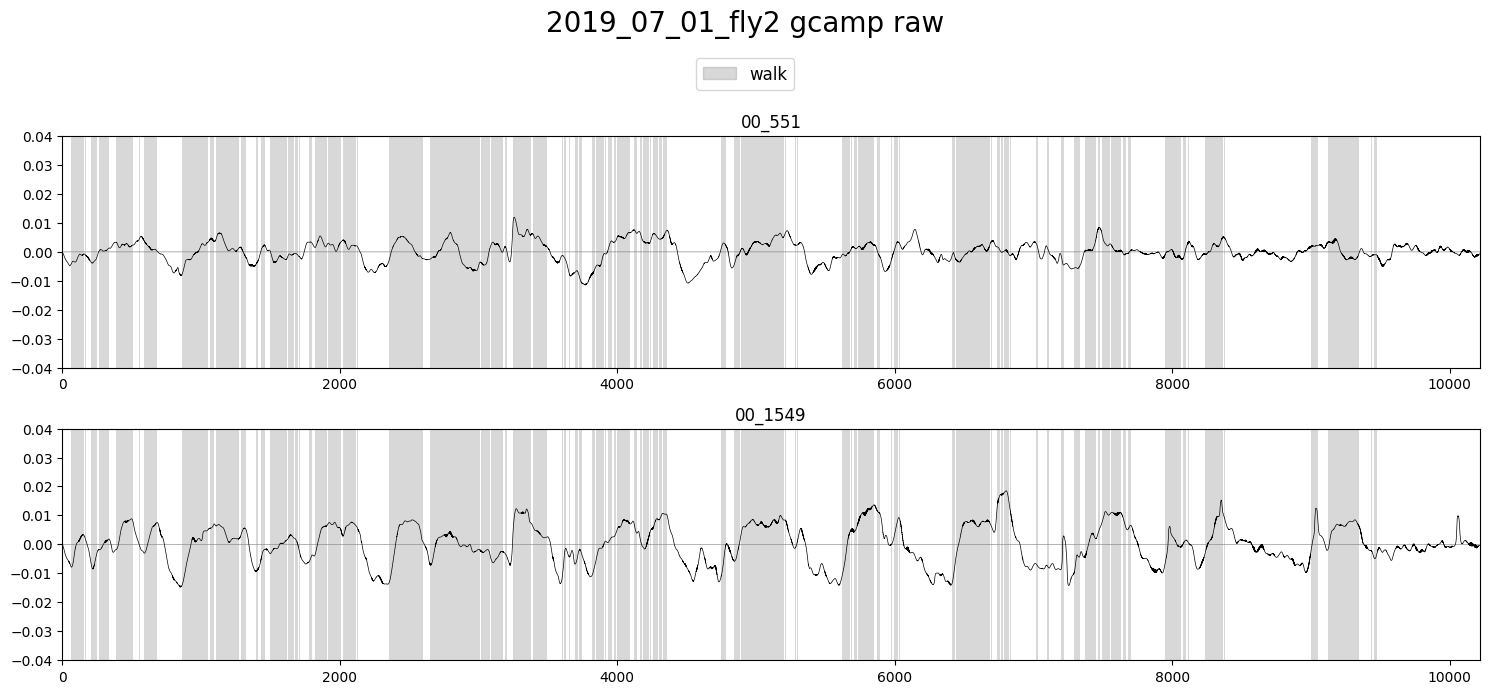

In [36]:
splits = 5
plot_utils.plot_traces(
	f'{filenames[file_ids.index(plot_id)]} gcamp raw',
	states[file_ids.index(plot_id)][['walk']],
	traces[file_ids.index(plot_id)][neurons_handpicked],
	label='walk', plots_per_row=1, ylimits=(-0.04, 0.04),
	save_name=None)  #'GCAMP_RAW'

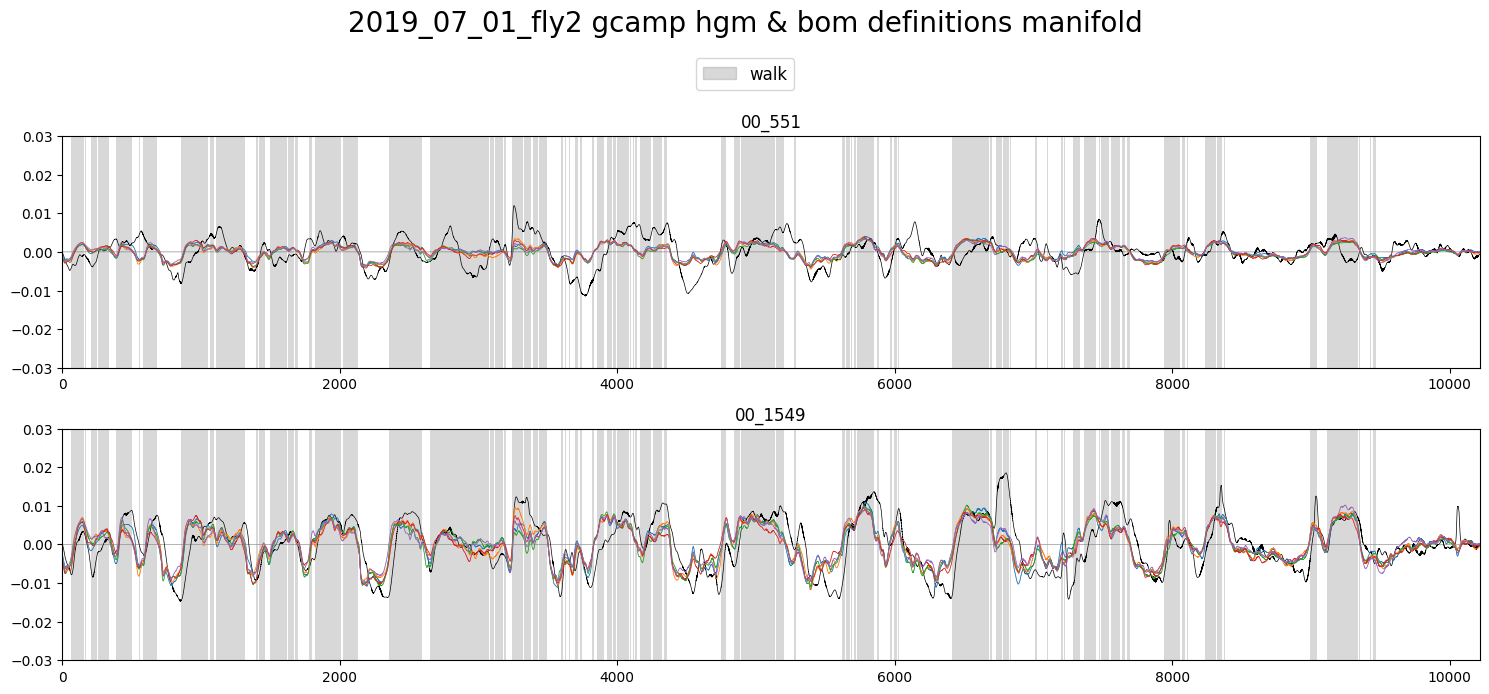

In [37]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames[file_ids.index(plot_id)]} gcamp hgm & bom definitions manifold',
	states[file_ids.index(plot_id)][['walk']],
	traces[file_ids.index(plot_id)][neurons_handpicked],
	[hgms_rec_full[file_ids.index(plot_id)][i][neurons_handpicked] for i in range(splits)],
	[boms_rec_full[file_ids.index(plot_id)][i][neurons_handpicked] for i in range(splits)],
	label='walk', plot_first=True, plots_per_row=1, ylimits=(-0.03, 0.03),
	save_name=None)  #'GCAMP_MAN'

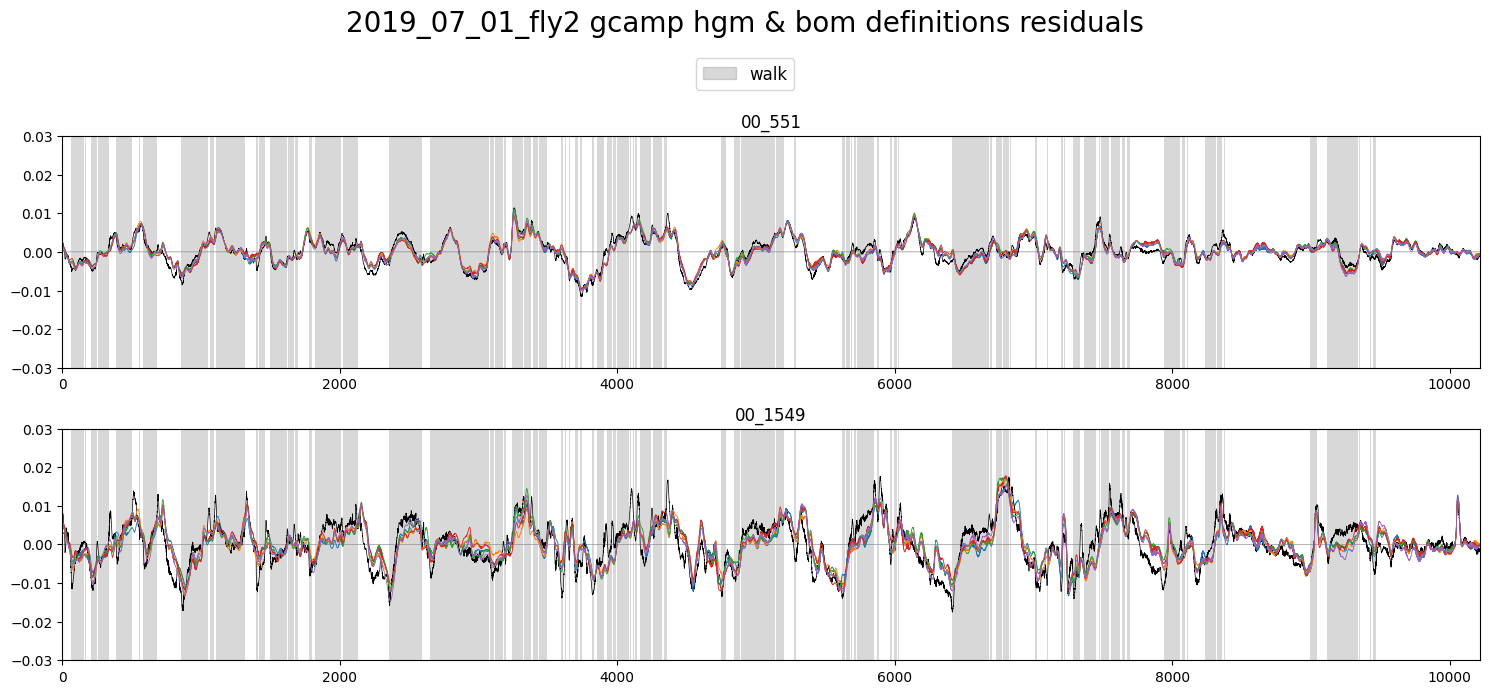

In [38]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames[file_ids.index(plot_id)]} gcamp hgm & bom definitions residuals',
	states[file_ids.index(plot_id)][['walk']],
	traces_cca_res[file_ids.index(plot_id)][neurons_handpicked],
	[hgms_res_full[file_ids.index(plot_id)][i][neurons_handpicked] for i in range(splits)],
	[boms_res_full[file_ids.index(plot_id)][i][neurons_handpicked] for i in range(splits)],
	label='walk', plot_first=True, plots_per_row=1, ylimits=(-0.03, 0.03),
	save_name=None)  #'GCAMP_RES'

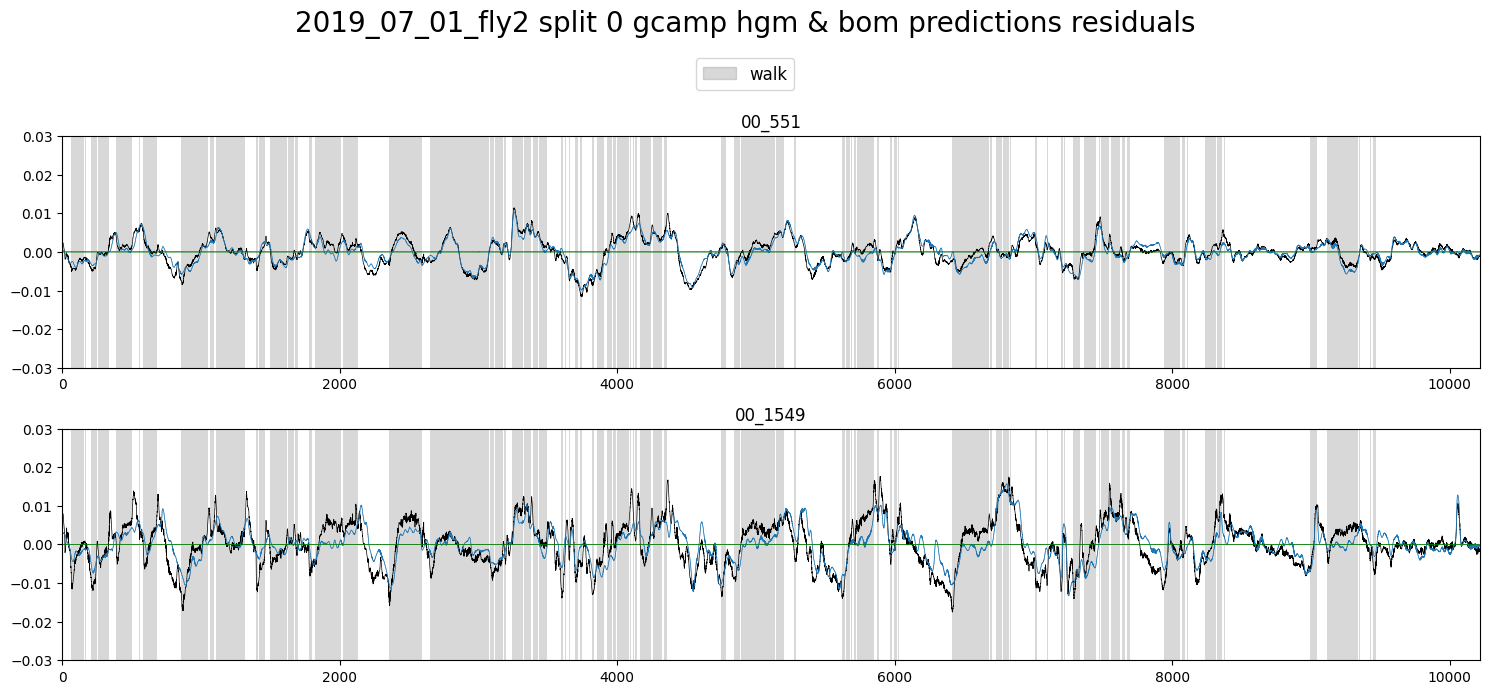

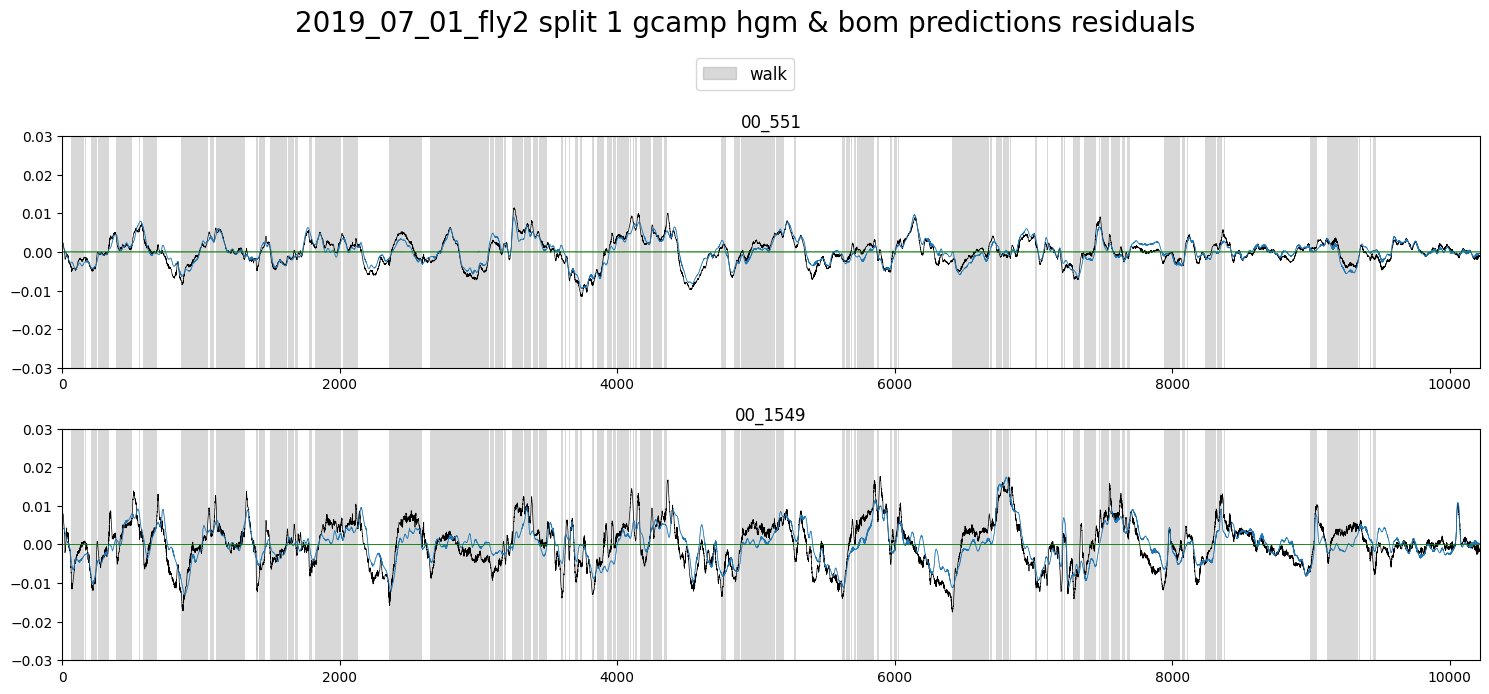

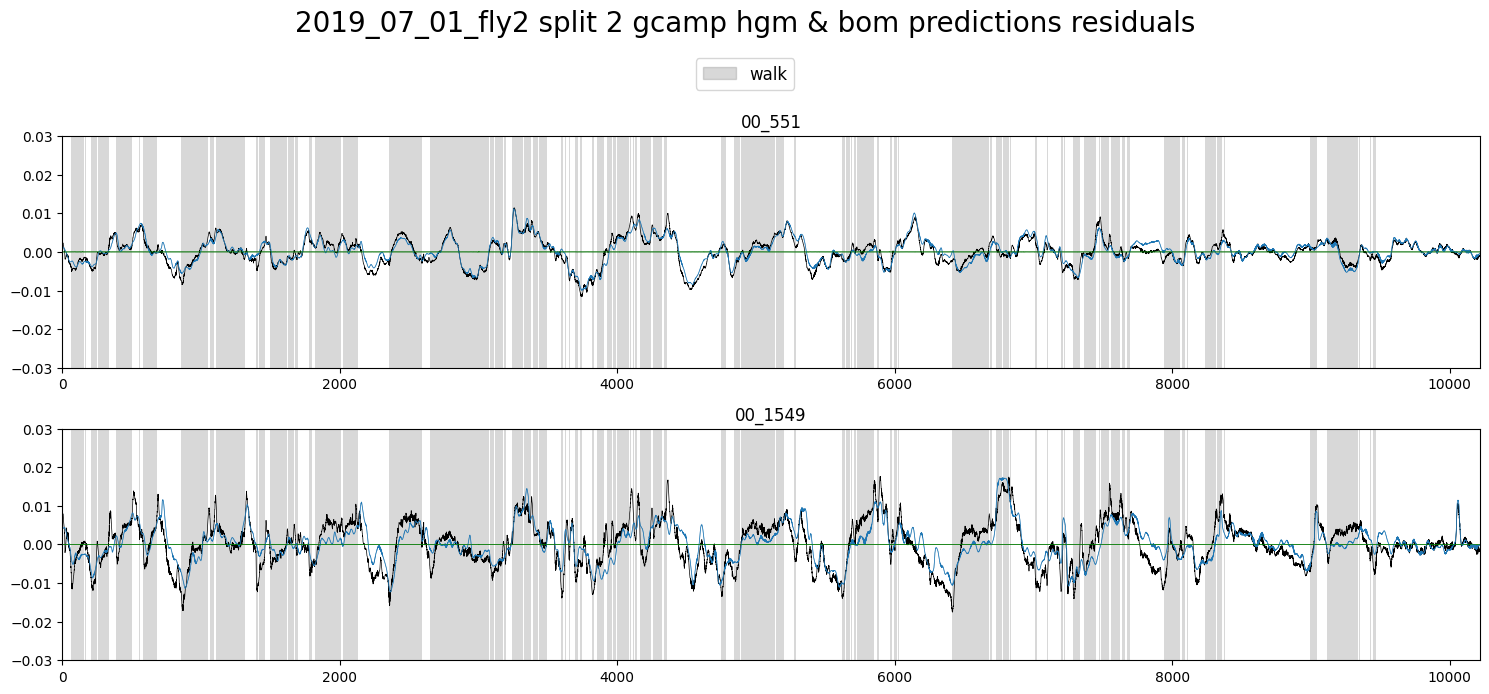

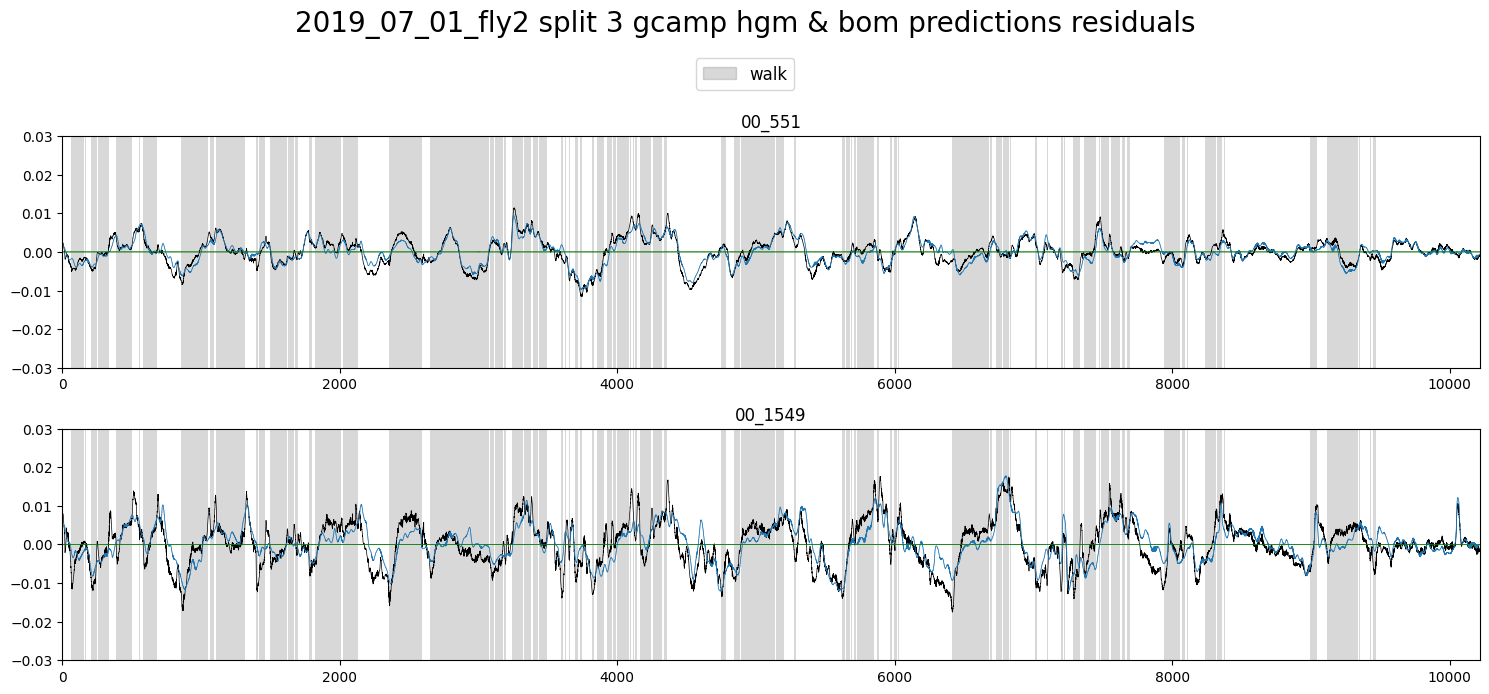

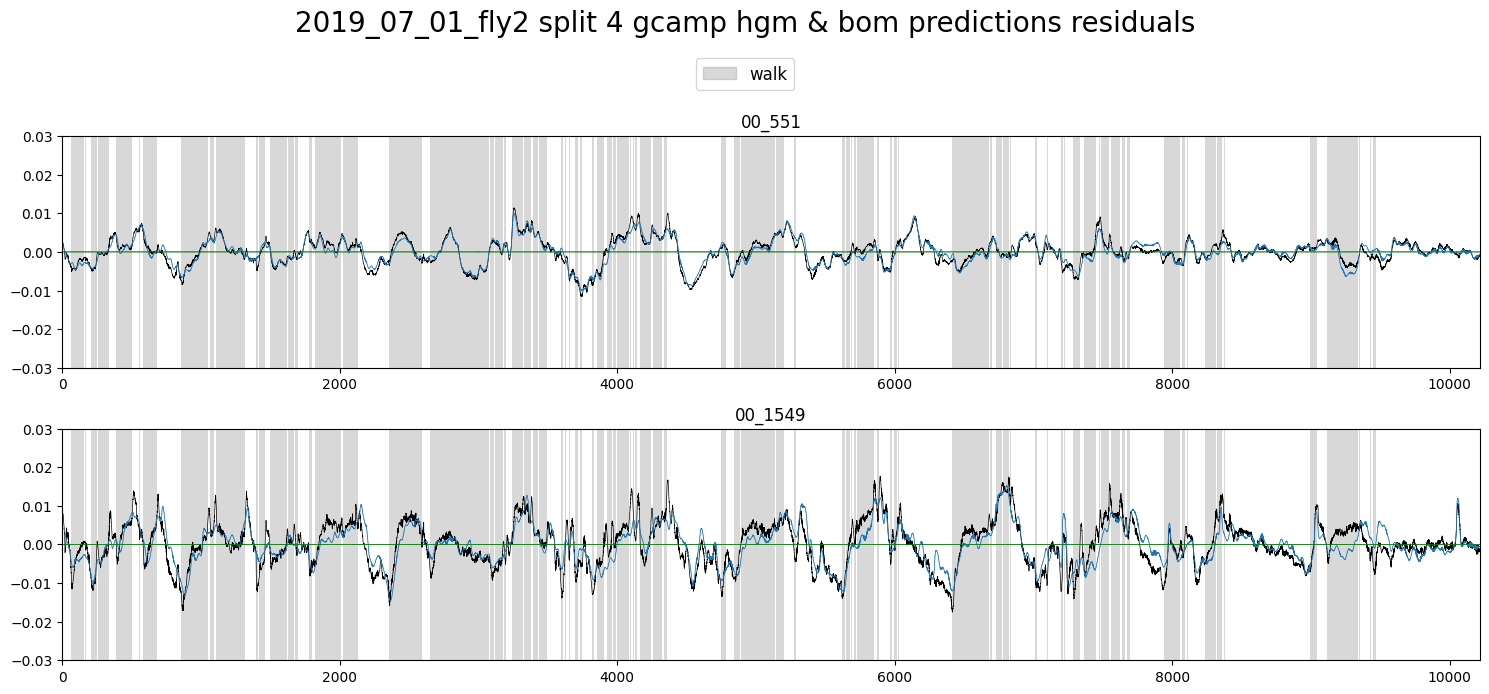

In [39]:
for i in range(5):
	plot_utils.plot_traces_comparisons(
		f'{filenames[file_ids.index(plot_id)]} split {i} gcamp hgm & bom predictions residuals',
		states[file_ids.index(plot_id)][['walk']],
		traces_cca_res[file_ids.index(plot_id)][neurons_handpicked],
		[hgms_res_full[file_ids.index(plot_id)][i][neurons_handpicked],
		 hgms_pres_full[file_ids.index(plot_id)][i][neurons_handpicked]],
		[boms_res_full[file_ids.index(plot_id)][i][neurons_handpicked],
		 boms_pres_full[file_ids.index(plot_id)][i][neurons_handpicked]],
		label='walk', plot_first=True, plots_per_row=1, ylimits=(-0.03, 0.03),
		save_name=None)  #f'GCAMP_PRES_S{i}'